# Trabalho Bimestral

Jonatan Portes

Projeto Final: Análise Exploratória de Dados.

1 - Contexto: Apresente brevemente sobre o que se trata a base escolhida e gere algumas informações sobre a base como a função .info() .

A base escolhida tem 6.433 corridas de táxi feitas em Nova York entre o fim de fevereiro e março de 2019, com táxis amarelos (yellow) e verdes (green). Os dados são da comissão de táxis da cidade (NYC TLC) e baixei a versão do repositório seaborn-data no GitHub.

Cada linha é uma corrida, com horário de embarque e desembarque, número de passageiros, distância em milhas, tarifa, gorjeta, pedágio e valor total (em dólares), forma de pagamento e as zonas e bairros de origem e destino.

Quero descobrir em quais bairros saem mais corridas, onde a corrida custa mais e se a forma de pagamento muda a gorjeta.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

dataframe_taxis = pd.read_csv("jonatan_portes_taxis.csv")
print("Base de dados carregada com sucesso!")
print(f"Linhas e colunas: {dataframe_taxis.shape}")

Base de dados carregada com sucesso!
Linhas e colunas: (6433, 14)


In [2]:
# Mostrando as 5 primeiras linhas
dataframe_taxis.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [3]:
# Resumo da estrutura (tipos de dados e valores nulos)
dataframe_taxis.info()

<class 'pandas.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   pickup           6433 non-null   str    
 1   dropoff          6433 non-null   str    
 2   passengers       6433 non-null   int64  
 3   distance         6433 non-null   float64
 4   fare             6433 non-null   float64
 5   tip              6433 non-null   float64
 6   tolls            6433 non-null   float64
 7   total            6433 non-null   float64
 8   color            6433 non-null   str    
 9   payment          6389 non-null   str    
 10  pickup_zone      6407 non-null   str    
 11  dropoff_zone     6388 non-null   str    
 12  pickup_borough   6407 non-null   str    
 13  dropoff_borough  6388 non-null   str    
dtypes: float64(5), int64(1), str(8)
memory usage: 703.7 KB


In [4]:
print("Valores nulos por coluna:")
print(dataframe_taxis.isnull().sum())

# Sem forma de pagamento ou bairro a corrida não entra na análise, então removo essas linhas
dataframe_taxis = dataframe_taxis.dropna()
print(f"\nCorridas depois da limpeza: {len(dataframe_taxis)}")

Valores nulos por coluna:
pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

Corridas depois da limpeza: 6341


2 - Estatísticas: Utilize as funções do Pandas para gerar estatísticas descritivas (médias, contagens, valores máximos e mínimos).

In [5]:
dataframe_taxis[['passengers', 'distance', 'fare', 'tip', 'total']].describe()

,passengers,distance,fare,tip,total
count,6341.000000,6341.000000,6341.000000,6341.000000,6341.000000
mean,1.544078,2.997707,12.887931,1.972703,18.310263
std,1.207948,3.719775,10.722249,2.361897,12.950365
min,0.000000,0.000000,1.000000,0.000000,1.300000
25%,1.000000,0.990000,6.500000,0.000000,10.800000
50%,1.000000,1.650000,9.500000,1.750000,14.160000
75%,2.000000,3.200000,15.000000,2.820000,20.300000
max,6.000000,36.700000,150.000000,23.190000,174.820000


In [6]:
media_distancia = dataframe_taxis['distance'].mean()
media_tarifa = dataframe_taxis['fare'].mean()
mediana_tarifa = dataframe_taxis['fare'].median()
maior_total = dataframe_taxis['total'].max()
menor_total = dataframe_taxis['total'].min()
moda_passageiros = dataframe_taxis['passengers'].mode()[0]

print(f"Distância média: {media_distancia:.2f} milhas")
print(f"Tarifa média: $ {media_tarifa:.2f}")
print(f"Mediana da tarifa: $ {mediana_tarifa:.2f}")
print(f"Maior valor total pago: $ {maior_total:.2f}")
print(f"Menor valor total pago: $ {menor_total:.2f}")
print(f"Quantidade de passageiros mais comum: {moda_passageiros}")

Distância média: 3.00 milhas
Tarifa média: $ 12.89
Mediana da tarifa: $ 9.50
Maior valor total pago: $ 174.82
Menor valor total pago: $ 1.30
Quantidade de passageiros mais comum: 1


In [7]:
# Contagem de corridas por cor do táxi e por forma de pagamento
print("Corridas por cor do táxi:")
print(dataframe_taxis['color'].value_counts())

print("\nCorridas por forma de pagamento:")
print(dataframe_taxis['payment'].value_counts())

Corridas por cor do táxi:
color
yellow    5373
green      968
Name: count, dtype: int64

Corridas por forma de pagamento:
payment
credit card    4546
cash           1795
Name: count, dtype: int64


In [8]:
# Tarifa média por bairro de embarque
tarifa_por_bairro = dataframe_taxis.groupby('pickup_borough')['fare'].mean()
tarifa_por_bairro = tarifa_por_bairro.sort_values(ascending=False)
print("Tarifa média por bairro de embarque:")
print(tarifa_por_bairro.round(2))

# Distância média por bairro de embarque
distancia_por_bairro = dataframe_taxis.groupby('pickup_borough')['distance'].mean()
print("\nDistância média por bairro de embarque (milhas):")
print(distancia_por_bairro.round(2))

# Gorjeta média por forma de pagamento
gorjeta_por_pagamento = dataframe_taxis.groupby('payment')['tip'].mean()
print("\nGorjeta média por forma de pagamento:")
print(gorjeta_por_pagamento.round(2))

Tarifa média por bairro de embarque:
pickup_borough
Queens       24.18
Bronx        21.00
Brooklyn     16.45
Manhattan    11.10
Name: fare, dtype: float64

Distância média por bairro de embarque (milhas):
pickup_borough
Bronx        5.73
Brooklyn     4.11
Manhattan    2.34
Queens       7.31
Name: distance, dtype: float64

Gorjeta média por forma de pagamento:
payment
cash           0.00
credit card    2.75
Name: tip, dtype: float64


3 - Visualização: Crie pelo menos dois gráficos customizados (com título, eixos e cores) que revele um padrão ou curiosidade sobre os dados.

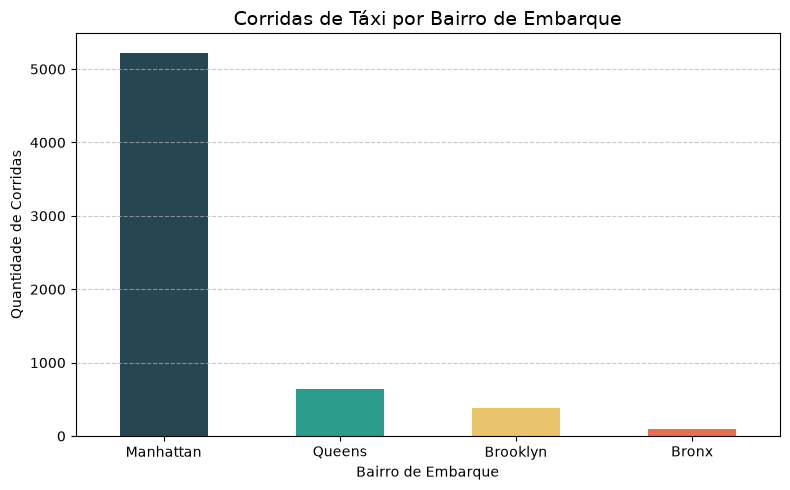

In [9]:
# Gráfico 1: quantidade de corridas por bairro de embarque
dataframe_taxis['pickup_borough'].value_counts().plot(
    kind='bar',
    figsize=(8, 5),
    color=['#264653', '#2a9d8f', '#e9c46a', '#e76f51']
)
plt.title('Corridas de Táxi por Bairro de Embarque', fontsize=14)
plt.xlabel('Bairro de Embarque')
plt.ylabel('Quantidade de Corridas')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Manhattan concentra a grande maioria das corridas. Os outros bairros juntos não chegam a 1.200.

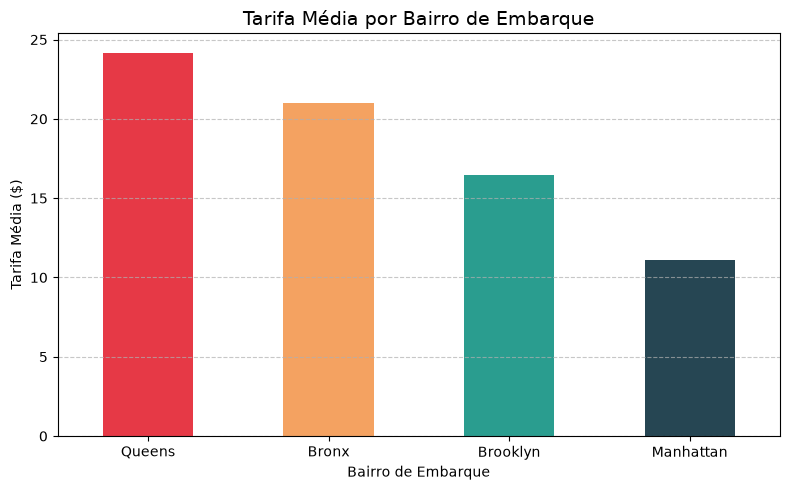

In [10]:
# Gráfico 2: tarifa média por bairro de embarque
ax = tarifa_por_bairro.plot(
    kind='bar',
    figsize=(8, 5),
    color=['#e63946', '#f4a261', '#2a9d8f', '#264653']
)
ax.set_title('Tarifa Média por Bairro de Embarque', fontsize=14)
ax.set_xlabel('Bairro de Embarque')
ax.set_ylabel('Tarifa Média ($)')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Apesar de ter mais corridas, Manhattan tem a menor tarifa média, cerca de 11 dólares. Queens e Bronx passam de 20 dólares. A distância média explica isso: quem embarca em Manhattan anda em média 2,3 milhas, e em Queens são 7,3 milhas.

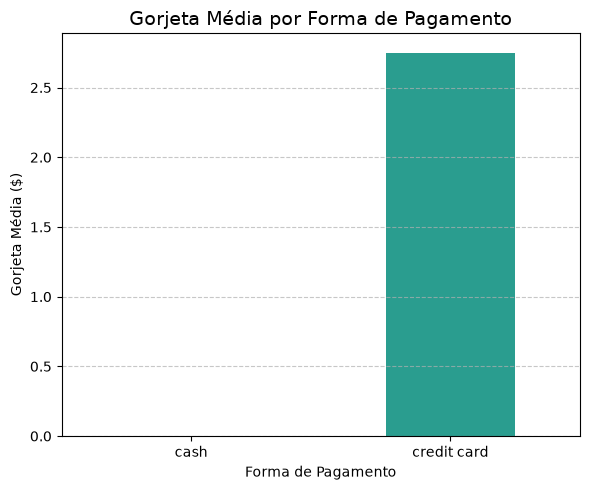

In [11]:
# Gráfico 3: gorjeta média por forma de pagamento
ax = gorjeta_por_pagamento.plot(
    kind='bar',
    figsize=(6, 5),
    color=['#8d99ae', '#2a9d8f']
)
ax.set_title('Gorjeta Média por Forma de Pagamento', fontsize=14)
ax.set_xlabel('Forma de Pagamento')
ax.set_ylabel('Gorjeta Média ($)')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

A curiosidade da base: nas corridas pagas em dinheiro a gorjeta registrada é sempre zero. Isso não quer dizer que ninguém deu gorjeta, só que a gorjeta em dinheiro não fica registrada no sistema. No cartão a média é de 2,75 dólares por corrida.